# Análise Exploratória de Dados — NPS e experiência do cliente

## Contexto e objetivo

A nota que o cliente dá depois de uma compra é um sinal importante sobre a experiência que teve. Nesta análise, vamos olhar para os dados como um todo e procurar entender onde aparecem os principais sinais de satisfação ou insatisfação — desde a entrega até o contato com o atendimento.

A unidade analisada é o **registro de pedido**. Assim, os percentuais apresentados descrevem os pedidos da base e não necessariamente clientes únicos.

### Perguntas que queremos responder

1. Como estão distribuídas as notas e as categorias de NPS?
2. Há problemas nos dados que possam atrapalhar a leitura dos resultados?
3. Atrasos, tempo de entrega, frete e tentativas aparecem relacionados à nota?
4. Reclamações, contatos e tempo de resolução acompanham notas mais baixas?
5. Há diferenças relevantes entre regiões, perfis de clientes ou tipos de pedido?
6. O que vale investigar primeiro e quais cuidados precisamos tomar antes de treinar um modelo?

**Um cuidado importante:** esta é uma análise exploratória. Uma associação entre duas variáveis não prova que uma cause a outra, nem garante que será útil para prever a satisfação em novos dados.

---

## 1. Bibliotecas, configuração e carregamento dos dados

Por padrão, o notebook usa `data/processed/desafio_nps_fase_1_clean.csv`. O caminho é localizado a partir da pasta em que o Jupyter foi aberto, para facilitar a execução tanto pela raiz do projeto quanto pela pasta `notebooks/`. Se a base estiver em outro local, o caminho pode ser informado pela variável de ambiente `NPS_DATA_PATH`.

In [1]:
from pathlib import Path
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
RANDOM_STATE = 42

def localizar_base():
    caminho_env = os.getenv("NPS_DATA_PATH")
    if caminho_env:
        caminho = Path(caminho_env).expanduser()
        if caminho.exists():
            return caminho.resolve()
        raise FileNotFoundError(f"NPS_DATA_PATH foi definido, mas o arquivo não existe: {caminho}")

    cwd = Path.cwd().resolve()
    candidatos = []
    for pasta in [cwd, *cwd.parents]:
        candidatos.extend([
            pasta / "data" / "processed" / "desafio_nps_fase_1_clean.csv",
            pasta / "Case_nps_preditivo_fase_tech_fiap" / "data" / "processed" / "desafio_nps_fase_1_clean.csv",
        ])
    for caminho in candidatos:
        if caminho.exists():
            return caminho.resolve()
    raise FileNotFoundError(
        "Não encontrei data/processed/desafio_nps_fase_1_clean.csv. "
        "Execute primeiro o notebook de limpeza ou defina NPS_DATA_PATH."
    )

CAMINHO_BASE = localizar_base()
df_original = pd.read_csv(CAMINHO_BASE)
df = df_original.copy()

print(f"Arquivo carregado: {CAMINHO_BASE}")
print(f"Dimensões: {df.shape[0]:,} registros × {df.shape[1]} colunas")
display(df.head())

Arquivo carregado: /mnt/data/nps_eda_rebuild/Case_nps_preditivo_fase_tech_fiap/data/processed/desafio_nps_fase_1_clean.csv
Dimensões: 2,465 registros × 19 colunas


,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


## 2. Conhecendo a base e conferindo sua qualidade

Antes de tirar conclusões sobre a satisfação, vale conferir com que dados estamos trabalhando. Aqui olhamos para as dimensões da base, os tipos das colunas, os valores ausentes, as duplicidades e algumas regras básicas de coerência.

A ideia não é repetir a limpeza nem excluir registros automaticamente. É entender quais pontos podem afetar a leitura dos resultados e precisam ser levados em conta nas próximas etapas.

In [2]:
print("Tipos de dados:")
display(df.dtypes.rename("tipo").to_frame())

qualidade = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "% nulos": (df.isna().mean() * 100).round(2),
    "valores distintos": df.nunique(dropna=False)
}).sort_values(["nulos", "valores distintos"], ascending=[False, True])
display(qualidade)

print(f"Linhas totalmente duplicadas: {df.duplicated().sum():,}")
for coluna in ["customer_id", "order_id"]:
    if coluna in df.columns:
        print(f"IDs duplicados em {coluna}: {df[coluna].duplicated().sum():,}")

Tipos de dados:


,tipo
customer_id,int64
customer_age,int64
customer_region,object
customer_tenure_months,int64
order_id,int64
order_value,float64
items_quantity,int64
discount_value,float64
payment_installments,int64
delivery_time_days,int64


,tipo,nulos,% nulos,valores distintos
repeat_purchase_30d,int64,0,0.0,2
delivery_attempts,int64,0,0.0,3
customer_region,object,0,0.0,5
items_quantity,int64,0,0.0,6
customer_service_contacts,int64,0,0.0,8
delivery_delay_days,int64,0,0.0,9
payment_installments,int64,0,0.0,11
resolution_time_days,int64,0,0.0,12
complaints_count,int64,0,0.0,12
delivery_time_days,int64,0,0.0,13


Linhas totalmente duplicadas: 0
IDs duplicados em customer_id: 0
IDs duplicados em order_id: 0


In [3]:
colunas_numericas = df.select_dtypes(include=np.number).columns.tolist()
display(df[colunas_numericas].describe().T.round(2))

validacoes = {}
if "nps_score" in df:
    validacoes["nps fora de [0, 10]"] = int((~df["nps_score"].between(0, 10)).sum())
if "csat_internal_score" in df:
    validacoes["CSAT fora de [0, 10]"] = int((~df["csat_internal_score"].between(0, 10)).sum())
if "delivery_attempts" in df:
    validacoes["tentativas fora de {1, 2, 3}"] = int((~df["delivery_attempts"].isin([1, 2, 3])).sum())
if "repeat_purchase_30d" in df:
    validacoes["recompra fora de {0, 1}"] = int((~df["repeat_purchase_30d"].isin([0, 1])).sum())
if "delivery_delay_days" in df:
    validacoes["atraso negativo"] = int((df["delivery_delay_days"] < 0).sum())
if "discount_value" in df and "order_value" in df:
    validacoes["desconto maior que valor do pedido"] = int((df["discount_value"] > df["order_value"]).sum())
display(pd.Series(validacoes, name="ocorrências").to_frame())

,count,mean,std,min,25%,50%,75%,max
customer_id,2465.0,1253.19,721.28,1.00,629.00,1254.00,1879.00,2500.00
customer_age,2465.0,43.32,14.90,18.00,31.00,43.00,56.00,69.00
customer_tenure_months,2465.0,61.30,34.49,1.00,31.00,62.00,91.00,119.00
order_id,2465.0,51253.19,721.28,50001.00,50629.00,51254.00,51879.00,52500.00
order_value,2465.0,439.72,288.14,14.58,225.35,379.89,584.77,1983.81
items_quantity,2465.0,3.47,1.69,1.00,2.00,3.00,5.00,6.00
discount_value,2465.0,29.04,28.41,0.02,8.72,20.51,40.03,230.33
payment_installments,2465.0,6.00,3.16,1.00,3.00,6.00,9.00,11.00
delivery_time_days,2465.0,8.02,3.77,2.00,5.00,8.00,11.00,14.00
delivery_delay_days,2465.0,2.19,1.46,0.00,1.00,2.00,3.00,8.00


,ocorrências
"nps fora de [0, 10]",0
"CSAT fora de [0, 10]",0
"tentativas fora de {1, 2, 3}",0
"recompra fora de {0, 1}",0
atraso negativo,0
desconto maior que valor do pedido,0


### O que observar na qualidade dos dados

Ausência de valores e duplicidades são apenas parte da história. Mesmo uma base sem valores nulos pode ter campos com definições pouco claras ou combinações que precisam ser confirmadas com a área de negócio. Por isso, os registros sinalizados pelas regras de domínio são destacados para investigação, mas não são removidos automaticamente nesta análise.

## 3. Como está a satisfação dos clientes?

A nota individual (`nps_score`) e o NPS agregado são medidas diferentes. Para manter a mesma regra usada na API e nos notebooks de atendimento, a classificação adotada aqui é:

- **Detratores:** nota ≤ 6,5;
- **Passivos:** 6,5 < nota ≤ 8,5;
- **Promotores:** nota > 8,5.

Como as notas podem ter casas decimais, os limites são aplicados diretamente, sem arredondar os valores originais. O NPS agregado é calculado subtraindo o percentual de detratores do percentual de promotores e fica entre −100 e +100.

Nota média: 4.38/10
Mediana da nota: 4.40/10
NPS agregado: -74.28


,pedidos,percentual
categoria_nps,,
Detratores,1975,80.12
Passivos,346,14.04
Promotores,144,5.84


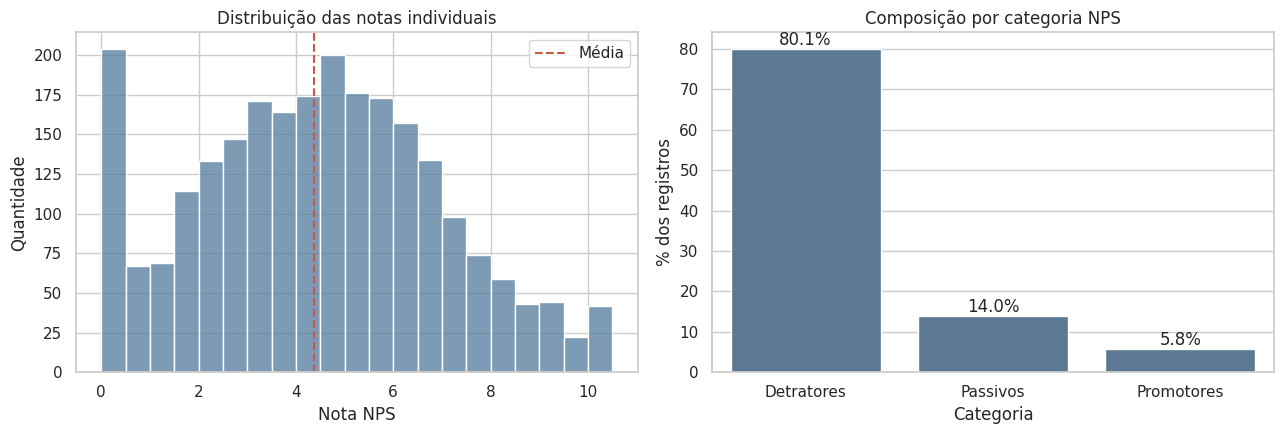

In [4]:
CORTE_DETRATOR = 6.5
CORTE_PROMOTOR = 8.5
ORDEM_NPS = ["Detratores", "Passivos", "Promotores"]

df["categoria_nps"] = pd.cut(
    df["nps_score"],
    bins=[-np.inf, CORTE_DETRATOR, CORTE_PROMOTOR, np.inf],
    labels=ORDEM_NPS,
    right=True
)

distribuicao_nps = (
    df["categoria_nps"].value_counts()
    .reindex(ORDEM_NPS, fill_value=0)
    .rename("pedidos").to_frame()
)
distribuicao_nps["percentual"] = distribuicao_nps["pedidos"] / len(df) * 100
pct = distribuicao_nps["percentual"]
nps_agregado = pct["Promotores"] - pct["Detratores"]
print(f"Nota média: {df['nps_score'].mean():.2f}/10")
print(f"Mediana da nota: {df['nps_score'].median():.2f}/10")
print(f"NPS agregado: {nps_agregado:.2f}")
display(distribuicao_nps.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["nps_score"], bins=np.arange(0, 10.6, 0.5), ax=axes[0], color="#527A9B")
axes[0].axvline(df["nps_score"].mean(), color="#C45B42", linestyle="--", label="Média")
axes[0].set(title="Distribuição das notas individuais", xlabel="Nota NPS", ylabel="Quantidade")
axes[0].legend()
sns.barplot(x=distribuicao_nps.index, y=distribuicao_nps["percentual"], ax=axes[1], color="#527A9B")
axes[1].set(title="Composição por categoria NPS", xlabel="Categoria", ylabel="% dos registros")
axes[1].bar_label(axes[1].containers[0], fmt="%.1f%%")
plt.tight_layout()
plt.show()

In [5]:
display(Markdown(
    f"**Interpretação:** a nota média é **{df['nps_score'].mean():.2f}/10** e o NPS agregado é **{nps_agregado:.1f}**. "
    f"Detratores representam **{pct['Detratores']:.1f}%** dos registros, passivos **{pct['Passivos']:.1f}%** "
    f"e promotores **{pct['Promotores']:.1f}%**. A leitura indica "
    f"{'predomínio de avaliações detratoras' if pct['Detratores'] > 50 else 'que detratores não representam mais da metade da amostra'}, "
    "sob a regra de classificação explicitada acima."
))

**Interpretação:** a nota média é **4.38/10** e o NPS agregado é **-74.3**. Detratores representam **80.1%** dos registros, passivos **14.0%** e promotores **5.8%**. A leitura indica predomínio de avaliações detratoras, sob a regra de classificação explicitada acima.

## 4. Logística: atrasos e experiência de entrega

É importante separar duas coisas: **quantos dias o pedido levou para chegar** e **quantos dias ficou além do prazo prometido**. Um pedido pode levar mais tempo que outro sem necessariamente estar atrasado; já a medida de atraso mostra o quanto a entrega passou do prazo esperado.

,valor
Pedidos analisados,2465.00
Pedidos com atraso (%),88.97
Atraso médio (dias),2.19
Mediana do atraso (dias),2.00
Pedidos com atraso ≥ 3 dias (%),38.46
Tempo médio de entrega (dias),8.02
Mediana do tempo de entrega (dias),8.00
Frete médio,38.29
Tentativas médias,2.01


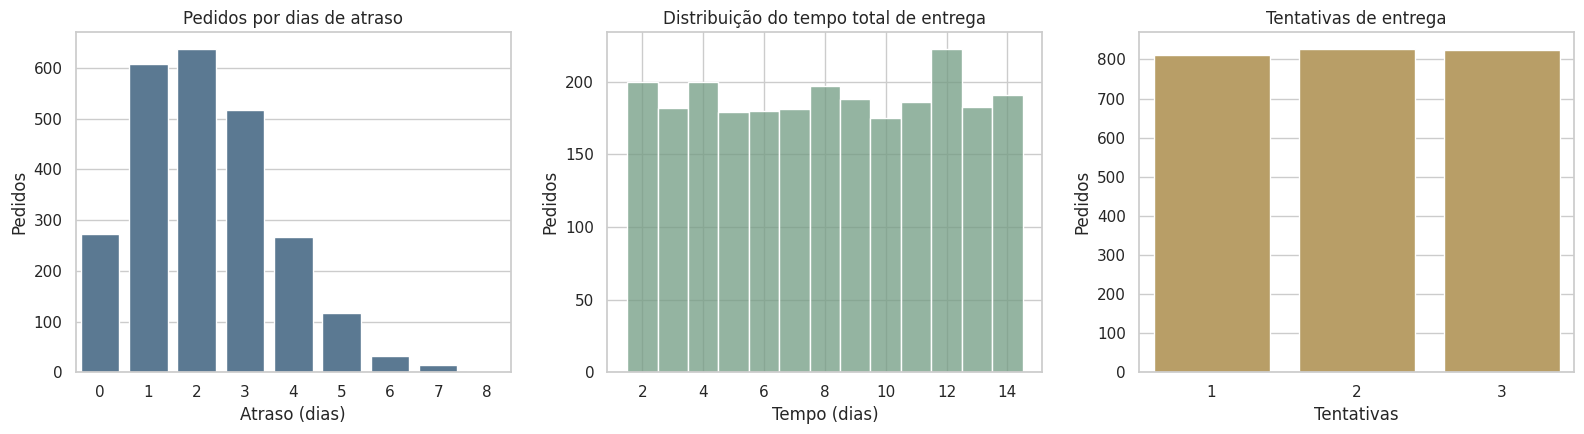

In [6]:
df["atrasado"] = df["delivery_delay_days"] > 0
df["faixa_atraso"] = pd.cut(
    df["delivery_delay_days"],
    bins=[-np.inf, 0, 1, 2, 4, np.inf],
    labels=["No prazo", "1 dia", "2 dias", "3–4 dias", "5+ dias"]
)
kpis_logistica = pd.Series({
    "Pedidos analisados": len(df),
    "Pedidos com atraso (%)": 100 * df["atrasado"].mean(),
    "Atraso médio (dias)": df["delivery_delay_days"].mean(),
    "Mediana do atraso (dias)": df["delivery_delay_days"].median(),
    "Pedidos com atraso ≥ 3 dias (%)": 100 * (df["delivery_delay_days"] >= 3).mean(),
    "Tempo médio de entrega (dias)": df["delivery_time_days"].mean(),
    "Mediana do tempo de entrega (dias)": df["delivery_time_days"].median(),
    "Frete médio": df["freight_value"].mean(),
    "Tentativas médias": df["delivery_attempts"].mean()
})
display(kpis_logistica.to_frame("valor").round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.countplot(data=df, x="delivery_delay_days", ax=axes[0], color="#527A9B")
axes[0].set(title="Pedidos por dias de atraso", xlabel="Atraso (dias)", ylabel="Pedidos")
sns.histplot(df["delivery_time_days"], discrete=True, ax=axes[1], color="#719B82")
axes[1].set(title="Distribuição do tempo total de entrega", xlabel="Tempo (dias)", ylabel="Pedidos")
sns.countplot(data=df, x="delivery_attempts", ax=axes[2], color="#C5A35A")
axes[2].set(title="Tentativas de entrega", xlabel="Tentativas", ylabel="Pedidos")
plt.tight_layout()
plt.show()

,pedidos,nota_media,nota_mediana,taxa_detratores,taxa_promotores,atraso_medio,tempo_entrega_medio
faixa_atraso,,,,,,,
No prazo,272,6.85,6.80,45.22,23.53,0.00,8.18
1 dia,607,5.55,5.50,66.89,9.72,1.00,7.92
2 dias,638,4.59,4.65,83.07,2.82,2.00,8.05
3–4 dias,782,3.10,3.00,95.91,0.38,3.34,8.02
5+ dias,166,1.27,0.70,100.00,0.00,5.42,8.07


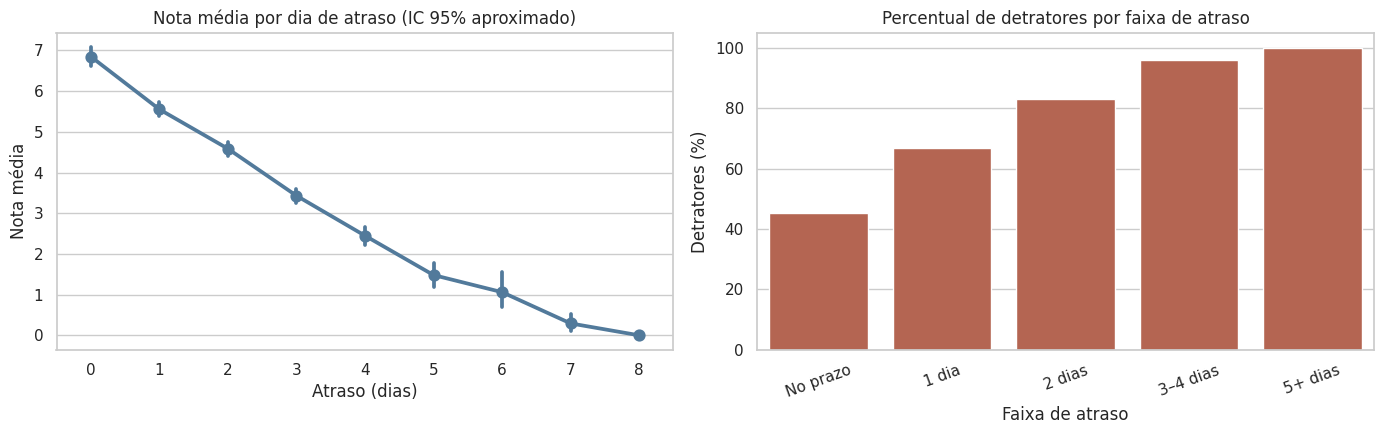

In [7]:
resumo_atraso = df.groupby("faixa_atraso", observed=False).agg(
    pedidos=("order_id", "count"),
    nota_media=("nps_score", "mean"),
    nota_mediana=("nps_score", "median"),
    taxa_detratores=("categoria_nps", lambda x: (x == "Detratores").mean() * 100),
    taxa_promotores=("categoria_nps", lambda x: (x == "Promotores").mean() * 100),
    atraso_medio=("delivery_delay_days", "mean"),
    tempo_entrega_medio=("delivery_time_days", "mean")
)
display(resumo_atraso.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.pointplot(data=df, x="delivery_delay_days", y="nps_score", errorbar=("ci", 95), ax=axes[0], color="#527A9B")
axes[0].set(title="Nota média por dia de atraso (IC 95% aproximado)", xlabel="Atraso (dias)", ylabel="Nota média")
sns.barplot(data=resumo_atraso.reset_index(), x="faixa_atraso", y="taxa_detratores", ax=axes[1], color="#C45B42")
axes[1].set(title="Percentual de detratores por faixa de atraso", xlabel="Faixa de atraso", ylabel="Detratores (%)")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

In [8]:
rho_atraso, p_atraso = stats.spearmanr(df["delivery_delay_days"], df["nps_score"])
rho_tempo, p_tempo = stats.spearmanr(df["delivery_time_days"], df["nps_score"])
rho_frete, p_frete = stats.spearmanr(df["freight_value"], df["nps_score"])
rho_tentativas, p_tentativas = stats.spearmanr(df["delivery_attempts"], df["nps_score"])
correlacoes_logisticas = pd.DataFrame({
    "variável": ["Dias de atraso", "Tempo total de entrega", "Valor do frete", "Tentativas de entrega"],
    "rho_spearman": [rho_atraso, rho_tempo, rho_frete, rho_tentativas],
    "p_valor": [p_atraso, p_tempo, p_frete, p_tentativas]
}).sort_values("rho_spearman")
display(correlacoes_logisticas.round(4))

,variável,rho_spearman,p_valor
0,Dias de atraso,-0.5878,0.0000
2,Valor do frete,-0.0390,0.0530
1,Tempo total de entrega,-0.0012,0.9531
3,Tentativas de entrega,0.0261,0.1958


### Como ler a relação entre atraso e nota

A correlação de Spearman ajuda a identificar se, conforme o atraso aumenta, a nota tende a subir ou cair, mesmo quando a relação não é linear. O valor de *p* indica evidência estatística, mas não diz sozinho se o efeito é importante para a operação. Por isso, a leitura também considera o tamanho da associação, a quantidade de pedidos em cada faixa e outros fatores que podem estar envolvidos.

## 5. Atendimento: reclamações, contatos e resolução

Reclamações, contatos repetidos e tempo de resolução podem ajudar a entender quais experiências acompanham notas mais baixas. Ainda assim, esses indicadores precisam ser lidos com cuidado: casos mais difíceis podem gerar mais contatos e levar mais tempo para serem resolvidos. Só com essas colunas não dá para concluir o que aconteceu primeiro ou atribuir a insatisfação diretamente ao atendimento.

,variável,rho_spearman,p_valor
0,Reclamações,-0.4877,0.0
1,Contatos com atendimento,-0.3326,0.0
2,Tempo de resolução,-0.1897,0.0
3,CSAT interno,0.5603,0.0


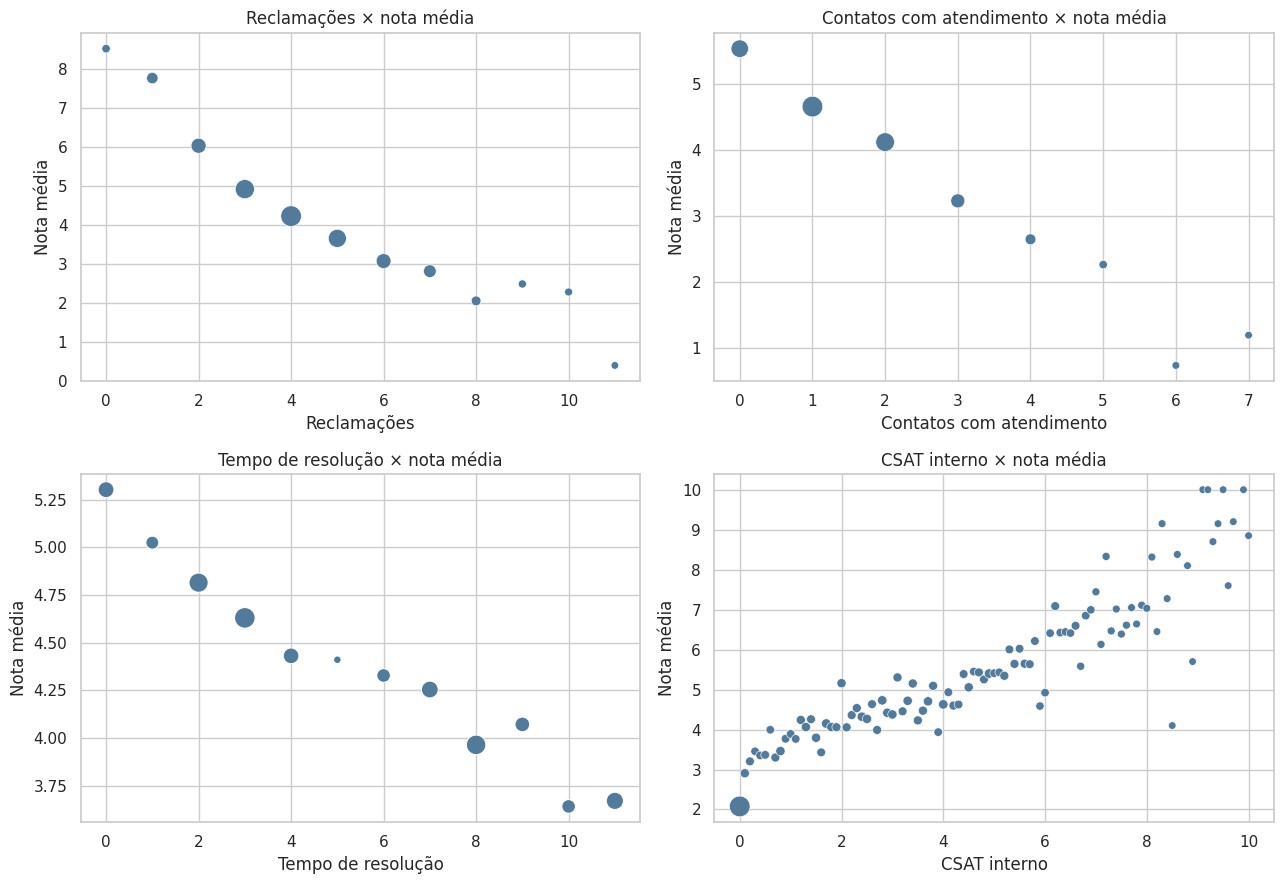

In [9]:
variaveis_atendimento = [
    ("complaints_count", "Reclamações"),
    ("customer_service_contacts", "Contatos com atendimento"),
    ("resolution_time_days", "Tempo de resolução"),
    ("csat_internal_score", "CSAT interno"),
]
cor_atendimento = []
for col, rotulo in variaveis_atendimento:
    rho, p = stats.spearmanr(df[col], df["nps_score"])
    cor_atendimento.append({"variável": rotulo, "rho_spearman": rho, "p_valor": p})
cor_atendimento = pd.DataFrame(cor_atendimento).sort_values("rho_spearman")
display(cor_atendimento.round(4))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (col, rotulo) in zip(axes.flat, variaveis_atendimento):
    resumo = df.groupby(col, observed=True).agg(
        pedidos=("nps_score", "size"),
        nota_media=("nps_score", "mean")
    ).reset_index()
    sns.scatterplot(data=resumo, x=col, y="nota_media", size="pedidos", sizes=(30, 220), ax=ax, legend=False, color="#527A9B")
    ax.set(title=f"{rotulo} × nota média", xlabel=rotulo, ylabel="Nota média")
plt.tight_layout()
plt.show()

faixa_contatos,0,1,2,3,4+
faixa_reclamacoes,,,,,
0,8.52,NaN,NaN,NaN,NaN
1,7.66,8.05,NaN,NaN,NaN
2–3,5.19,5.07,6.91,7.52,NaN
4–5,4.37,4.04,3.89,3.74,6.37
6+,3.65,3.57,3.20,2.77,2.41


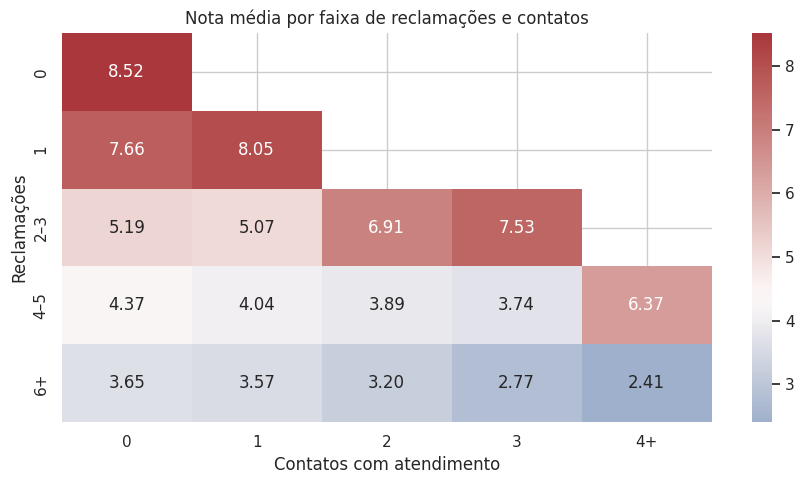

In [10]:
df["faixa_reclamacoes"] = pd.cut(
    df["complaints_count"], bins=[-np.inf, 0, 1, 3, 5, np.inf],
    labels=["0", "1", "2–3", "4–5", "6+"]
)
df["faixa_contatos"] = pd.cut(
    df["customer_service_contacts"], bins=[-np.inf, 0, 1, 2, 3, np.inf],
    labels=["0", "1", "2", "3", "4+"]
)
cruzamento_atendimento = pd.pivot_table(
    df, index="faixa_reclamacoes", columns="faixa_contatos",
    values="nps_score", aggfunc="mean", observed=False
)
display(cruzamento_atendimento.round(2))
plt.figure(figsize=(9, 5))
sns.heatmap(cruzamento_atendimento, annot=True, fmt=".2f", cmap="vlag", center=df["nps_score"].mean())
plt.title("Nota média por faixa de reclamações e contatos")
plt.xlabel("Contatos com atendimento")
plt.ylabel("Reclamações")
plt.tight_layout()
plt.show()

### O que os dados de atendimento permitem enxergar

Olhar para reclamações e contatos em conjunto ajuda a encontrar grupos que merecem uma análise mais próxima. Mas essas medidas podem contar parte da mesma história. Sem saber o motivo do chamado, a gravidade do caso, como ele foi resolvido e quando cada contato aconteceu, não conseguimos separar a complexidade do problema da qualidade do atendimento.

## 6. Perfil do cliente, região e características do pedido

Aqui comparamos as notas entre faixas de idade, tempo de relacionamento, regiões e características dos pedidos, como valor e quantidade de itens. A intenção é verificar se aparecem diferenças consistentes na base — não criar regras sobre pessoas a partir de pequenas diferenças nas médias.

,variável,rho_spearman,p_valor
7,freight_value,-0.0390,0.0530
1,customer_tenure_months,-0.0104,0.6041
0,customer_age,-0.0044,0.8255
6,delivery_time_days,-0.0012,0.9531
3,items_quantity,0.0071,0.7244
4,discount_value,0.0118,0.5569
8,delivery_attempts,0.0261,0.1958
5,payment_installments,0.0267,0.1851
2,order_value,0.0341,0.0902


,pedidos,nota_media,mediana_nota,atraso_medio,taxa_atraso,taxa_detratores,taxa_promotores
customer_region,,,,,,,
Sudeste,514,4.39,4.35,2.21,90.86,79.96,5.84
Sul,513,4.48,4.50,2.17,87.91,79.92,6.24
Norte,502,4.38,4.50,2.15,88.05,80.88,5.18
Nordeste,475,4.44,4.50,2.17,89.89,79.16,5.68
Centro-Oeste,461,4.20,4.20,2.24,88.07,80.69,6.29


Kruskal–Wallis para nota por região: H=3.577, p=0.4663


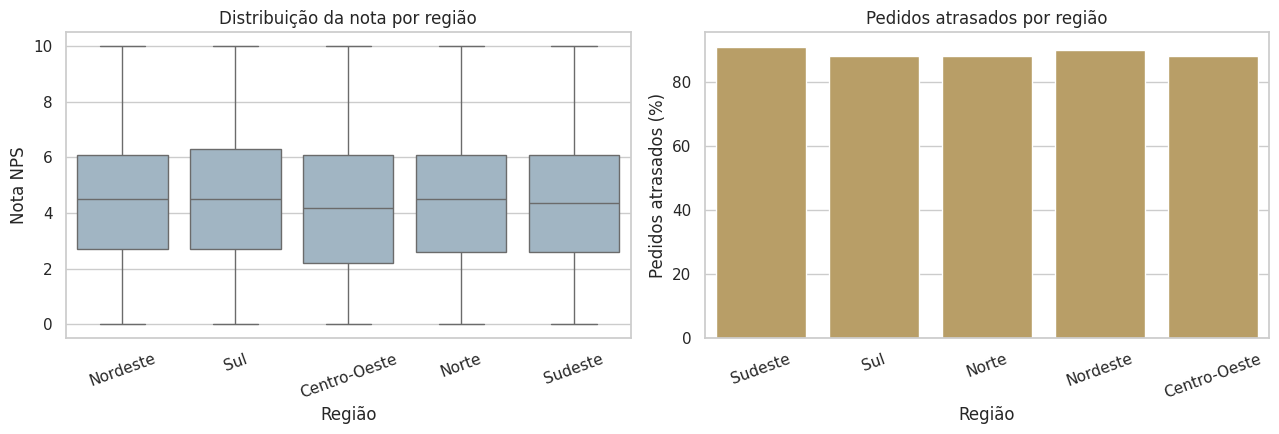

In [11]:
perfil_corr = []
for col in ["customer_age", "customer_tenure_months", "order_value", "items_quantity",
            "discount_value", "payment_installments", "delivery_time_days",
            "freight_value", "delivery_attempts"]:
    rho, p = stats.spearmanr(df[col], df["nps_score"])
    perfil_corr.append({"variável": col, "rho_spearman": rho, "p_valor": p})
display(pd.DataFrame(perfil_corr).sort_values("rho_spearman").round(4))

resumo_regiao = df.groupby("customer_region").agg(
    pedidos=("order_id", "count"),
    nota_media=("nps_score", "mean"),
    mediana_nota=("nps_score", "median"),
    atraso_medio=("delivery_delay_days", "mean"),
    taxa_atraso=("atrasado", lambda x: x.mean() * 100),
    taxa_detratores=("categoria_nps", lambda x: (x == "Detratores").mean() * 100),
    taxa_promotores=("categoria_nps", lambda x: (x == "Promotores").mean() * 100)
).sort_values("pedidos", ascending=False)
display(resumo_regiao.round(2))

grupos_regiao = [g["nps_score"].values for _, g in df.groupby("customer_region")]
h_regiao, p_regiao = stats.kruskal(*grupos_regiao)
print(f"Kruskal–Wallis para nota por região: H={h_regiao:.3f}, p={p_regiao:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df, x="customer_region", y="nps_score", ax=axes[0], color="#9BB6C9")
axes[0].set(title="Distribuição da nota por região", xlabel="Região", ylabel="Nota NPS")
axes[0].tick_params(axis="x", rotation=20)
sns.barplot(data=resumo_regiao.reset_index(), x="customer_region", y="taxa_atraso", ax=axes[1], color="#C5A35A")
axes[1].set(title="Pedidos atrasados por região", xlabel="Região", ylabel="Pedidos atrasados (%)")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

In [12]:
# Perfil por faixas, mantendo grupos com tamanho suficiente para uma leitura descritiva.
df["faixa_idade"] = pd.cut(df["customer_age"], bins=[-np.inf, 29, 39, 49, 59, np.inf],
                           labels=["Até 29", "30–39", "40–49", "50–59", "60+"])
df["faixa_valor_pedido"] = pd.qcut(df["order_value"], q=5, duplicates="drop")
resumo_perfil = []
for coluna in ["faixa_idade", "faixa_valor_pedido", "items_quantity", "customer_tenure_months"]:
    temp = df.groupby(coluna, observed=True).agg(
        pedidos=("order_id", "count"),
        nota_media=("nps_score", "mean"),
        taxa_detratores=("categoria_nps", lambda x: (x == "Detratores").mean() * 100)
    ).reset_index()
    temp.insert(0, "dimensão", coluna)
    temp = temp.rename(columns={coluna: "grupo"})
    resumo_perfil.append(temp)
display(pd.concat(resumo_perfil, ignore_index=True).round(2))

,dimensão,grupo,pedidos,nota_media,taxa_detratores
0,faixa_idade,Até 29,558,4.52,78.67
1,faixa_idade,30–39,490,4.24,82.04
2,faixa_idade,40–49,490,4.27,81.84
3,faixa_idade,50–59,472,4.37,78.39
4,faixa_idade,60+,455,4.49,79.78
...,...,...,...,...,...
130,customer_tenure_months,115,23,3.81,91.30
131,customer_tenure_months,116,21,3.68,90.48
132,customer_tenure_months,117,21,5.50,71.43
133,customer_tenure_months,118,26,4.05,92.31


## 7. Recompra e CSAT: bons indicadores, mas atenção ao momento em que ocorrem

O CSAT e a recompra ajudam a completar o retrato da experiência, mas há uma questão importante para a modelagem: a recompra em 30 dias acontece depois do pedido. Se a ideia for prever o NPS antes desse período, usar essa informação pode entregar ao modelo uma pista que ainda não estaria disponível naquele momento.

A separação muito forte entre recompra e nota também merece uma checagem. Ela pode refletir a maneira como os dados foram montados, e não necessariamente um padrão que se repetirá em outras bases.

In [13]:
resumo_recompra = df.groupby("repeat_purchase_30d").agg(
    pedidos=("order_id", "count"),
    nota_media=("nps_score", "mean"),
    nota_min=("nps_score", "min"),
    nota_max=("nps_score", "max"),
    csat_medio=("csat_internal_score", "mean"),
    taxa_detratores=("categoria_nps", lambda x: (x == "Detratores").mean() * 100)
)
resumo_recompra["percentual_pedidos"] = resumo_recompra["pedidos"] / len(df) * 100
display(resumo_recompra.round(2))

tabela_recompra_classe = pd.crosstab(df["categoria_nps"], df["repeat_purchase_30d"], normalize="index") * 100
display(tabela_recompra_classe.round(2).rename(columns={0: "Sem recompra (%)", 1: "Com recompra (%)"}))

print("Sobreposição recompra x nota:")
print("Registros com recompra e nota < 8:", int(((df["repeat_purchase_30d"] == 1) & (df["nps_score"] < 8)).sum()))
print("Registros sem recompra e nota >= 8:", int(((df["repeat_purchase_30d"] == 0) & (df["nps_score"] >= 8)).sum()))

,pedidos,nota_media,nota_min,nota_max,csat_medio,taxa_detratores,percentual_pedidos
repeat_purchase_30d,,,,,,,
0,2255,3.95,0.0,7.9,2.70,87.58,91.48
1,210,9.02,8.0,10.0,5.56,0.00,8.52


repeat_purchase_30d,Sem recompra (%),Com recompra (%)
categoria_nps,,
Detratores,100.00,0.00
Passivos,80.92,19.08
Promotores,0.00,100.00


Sobreposição recompra x nota:
Registros com recompra e nota < 8: 0
Registros sem recompra e nota >= 8: 0


## 8. Valores extremos e coerência entre as medidas logísticas

A regra de Tukey (1,5 × intervalo interquartil) ajuda a localizar valores distantes do restante da distribuição. Isso não significa que sejam erros: antes de excluir qualquer registro, seria necessário entender se aquele valor é possível no contexto do negócio.

Também comparamos atraso e tempo total de entrega. Quando os dois campos parecem incompatíveis, pode haver um problema de qualidade, mas também pode ser que cada coluna siga uma definição diferente. Vale confirmar isso antes de decidir por um tratamento.

,variável,mínimo,Q1,mediana,Q3,máximo,limite inferior,limite superior,outliers Tukey,% da variável
0,delivery_time_days,2.00,5.00,8.00,11.00,14.00,-4.00,20.00,0,0.00
1,delivery_delay_days,0.00,1.00,2.00,3.00,8.00,-2.00,6.00,17,0.69
2,freight_value,2.62,30.05,38.67,46.33,76.13,5.63,70.75,13,0.53
3,resolution_time_days,0.00,2.00,6.00,8.00,11.00,-7.00,17.00,0,0.00


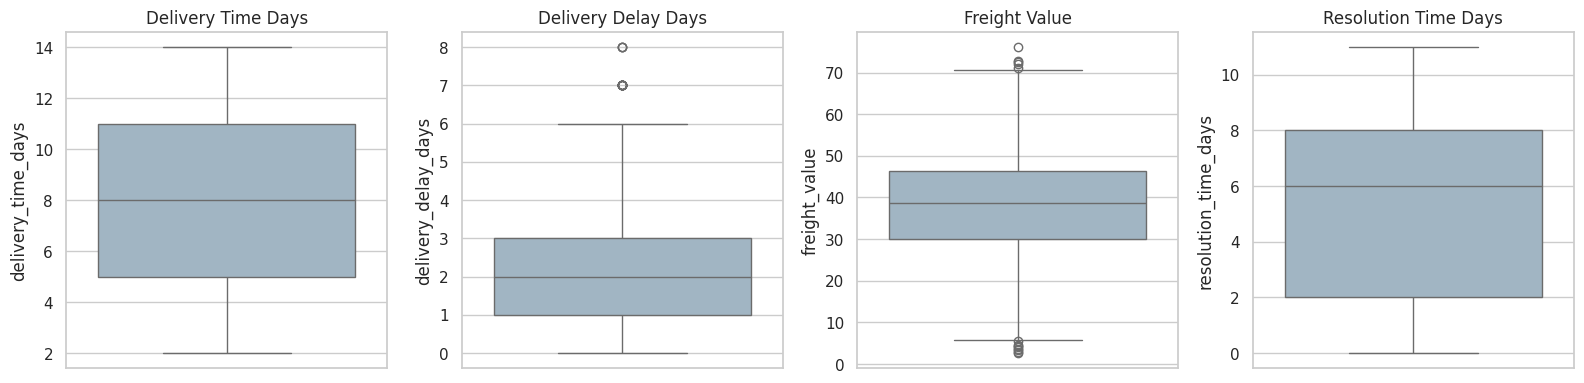

Spearman entre tempo total de entrega e atraso: rho=-0.003, p=0.8738


In [14]:
colunas_outliers = ["delivery_time_days", "delivery_delay_days", "freight_value", "resolution_time_days"]
linhas_outliers = []
for col in colunas_outliers:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mascara = (s < li) | (s > ls)
    linhas_outliers.append({
        "variável": col, "mínimo": s.min(), "Q1": q1, "mediana": s.median(), "Q3": q3,
        "máximo": s.max(), "limite inferior": li, "limite superior": ls,
        "outliers Tukey": int(mascara.sum()), "% da variável": 100 * mascara.mean()
    })
display(pd.DataFrame(linhas_outliers).round(2))

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, colunas_outliers):
    sns.boxplot(y=df[col], ax=ax, color="#9BB6C9")
    ax.set_title(col.replace("_", " ").title())
plt.tight_layout()
plt.show()

rho_coerencia, p_coerencia = stats.spearmanr(df["delivery_time_days"], df["delivery_delay_days"])
print(f"Spearman entre tempo total de entrega e atraso: rho={rho_coerencia:.3f}, p={p_coerencia:.4f}")

## 9. Onde vale investigar primeiro?

Uma taxa alta de detratores em um grupo pequeno nem sempre representa o maior problema para o negócio. Um grupo maior, mesmo com uma taxa um pouco menor, pode concentrar mais clientes insatisfeitos.

Por isso, a tabela combina o tamanho de cada grupo, a proporção de detratores dentro dele e a participação desse grupo no total de detratores. Use-a como ponto de partida para decidir o que investigar — não como prova de que uma variável causa a insatisfação.

In [15]:
priorizacao = df.groupby("faixa_atraso", observed=False).agg(
    pedidos=("order_id", "count"),
    detratores=("categoria_nps", lambda x: (x == "Detratores").sum()),
    taxa_detratores=("categoria_nps", lambda x: (x == "Detratores").mean() * 100),
    nota_media=("nps_score", "mean")
)
total_detratores = (df["categoria_nps"] == "Detratores").sum()
priorizacao["participacao_total_detratores"] = priorizacao["detratores"] / max(total_detratores, 1) * 100
priorizacao["participacao_pedidos"] = priorizacao["pedidos"] / len(df) * 100
display(priorizacao.sort_values("detratores", ascending=False).round(2))

# Cruzamento de região e gravidade do atraso para observar se o padrão é localizado ou disseminado.
segmentos = df.groupby(["customer_region", "faixa_atraso"], observed=False).agg(
    pedidos=("order_id", "count"),
    nota_media=("nps_score", "mean"),
    taxa_detratores=("categoria_nps", lambda x: (x == "Detratores").mean() * 100)
).reset_index()
display(segmentos.sort_values(["taxa_detratores", "pedidos"], ascending=[False, False]).head(12).round(2))

,pedidos,detratores,taxa_detratores,nota_media,participacao_total_detratores,participacao_pedidos
faixa_atraso,,,,,,
3–4 dias,782,750,95.91,3.10,37.97,31.72
2 dias,638,530,83.07,4.59,26.84,25.88
1 dia,607,406,66.89,5.55,20.56,24.62
5+ dias,166,166,100.00,1.27,8.41,6.73
No prazo,272,123,45.22,6.85,6.23,11.03


,customer_region,faixa_atraso,pedidos,nota_media,taxa_detratores
24,Sul,5+ dias,40,1.15,100.00
14,Norte,5+ dias,34,1.58,100.00
4,Centro-Oeste,5+ dias,32,1.14,100.00
19,Sudeste,5+ dias,31,1.25,100.00
9,Nordeste,5+ dias,29,1.24,100.00
13,Norte,3–4 dias,157,2.91,98.73
3,Centro-Oeste,3–4 dias,154,2.92,97.40
23,Sul,3–4 dias,151,3.28,97.35
8,Nordeste,3–4 dias,154,3.12,94.81
18,Sudeste,3–4 dias,166,3.26,91.57


## 10. O que os resultados contam quando vistos em conjunto

Nesta parte, reunimos os resultados das análises anteriores para montar uma visão geral da experiência do cliente. Os dados ajudam a apontar padrões e prioridades, mas algumas explicações ainda são hipóteses: para confirmá-las, serão necessários mais detalhes da operação e, quando possível, testes específicos.

In [16]:
# Síntese dinâmica gerada a partir dos resultados efetivamente calculados.
rho_reclamacoes, p_reclamacoes = stats.spearmanr(df["complaints_count"], df["nps_score"])
rho_contatos, p_contatos = stats.spearmanr(df["customer_service_contacts"], df["nps_score"])
rho_csat, p_csat = stats.spearmanr(df["csat_internal_score"], df["nps_score"])
atraso_pct = 100 * df["atrasado"].mean()
atraso_medio_positivos = df.loc[df["atrasado"], "delivery_delay_days"].mean()
taxa_det_sem_atraso = 100 * (df.loc[df["delivery_delay_days"] == 0, "categoria_nps"] == "Detratores").mean()
taxa_det_2dias = 100 * (df.loc[df["delivery_delay_days"] == 2, "categoria_nps"] == "Detratores").mean()
taxa_det_3mais = 100 * (df.loc[df["delivery_delay_days"] >= 3, "categoria_nps"] == "Detratores").mean()
nota_sem_atraso = df.loc[df["delivery_delay_days"] == 0, "nps_score"].mean()
nota_2dias = df.loc[df["delivery_delay_days"] == 2, "nps_score"].mean()
nota_3mais = df.loc[df["delivery_delay_days"] >= 3, "nps_score"].mean()

display(Markdown(f'''
### Principais evidências

1. **Satisfação geral:** a nota média é **{df["nps_score"].mean():.2f}/10** e o NPS agregado é **{nps_agregado:.1f}**, com **{pct["Detratores"]:.1f}%** de detratores sob a regra de classificação adotada.
2. **Atraso:** **{atraso_pct:.1f}%** dos pedidos apresentam atraso; entre pedidos atrasados, a média é **{atraso_medio_positivos:.2f} dias**. A associação entre atraso e nota é **Spearman ρ = {rho_atraso:.2f}**.
3. **Gravidade do atraso:** a nota média é **{nota_sem_atraso:.2f}** sem atraso, **{nota_2dias:.2f}** com dois dias e **{nota_3mais:.2f}** com três dias ou mais. A taxa de detratores correspondente é **{taxa_det_sem_atraso:.1f}%**, **{taxa_det_2dias:.1f}%** e **{taxa_det_3mais:.1f}%**.
4. **Atendimento:** Spearman entre reclamações e nota = **{rho_reclamacoes:.2f}**; entre contatos e nota = **{rho_contatos:.2f}**; entre CSAT e nota = **{rho_csat:.2f}**.
5. **Região:** o teste Kruskal–Wallis para nota por região resulta em **p = {p_regiao:.3f}**. Isso não fornece evidência estatística suficiente de diferenças de distribuição entre as regiões nesta amostra.
6. **Recompra:** a associação é descritiva e deve ser tratada com cautela por ser uma variável posterior ao pedido e por sua possível dependência com a regra de geração dos dados.
'''))


### Principais evidências

1. **Satisfação geral:** a nota média é **4.38/10** e o NPS agregado é **-74.3**, com **80.1%** de detratores sob a regra de classificação adotada.
2. **Atraso:** **89.0%** dos pedidos apresentam atraso; entre pedidos atrasados, a média é **2.46 dias**. A associação entre atraso e nota é **Spearman ρ = -0.59**.
3. **Gravidade do atraso:** a nota média é **6.85** sem atraso, **4.59** com dois dias e **2.78** com três dias ou mais. A taxa de detratores correspondente é **45.2%**, **83.1%** e **96.6%**.
4. **Atendimento:** Spearman entre reclamações e nota = **-0.49**; entre contatos e nota = **-0.33**; entre CSAT e nota = **0.56**.
5. **Região:** o teste Kruskal–Wallis para nota por região resulta em **p = 0.466**. Isso não fornece evidência estatística suficiente de diferenças de distribuição entre as regiões nesta amostra.
6. **Recompra:** a associação é descritiva e deve ser tratada com cautela por ser uma variável posterior ao pedido e por sua possível dependência com a regra de geração dos dados.


## 11. Próximos passos para o negócio e para a modelagem

### O que investigar na operação

1. **Entender de onde vêm os atrasos.** Seria útil ter o prazo prometido, as datas de pedido, postagem e entrega, além da transportadora, rota, centro de distribuição e eventos de cada etapa. Com as colunas atuais, não conseguimos apontar a causa raiz.
2. **Acompanhar os pedidos com dois dias ou mais de atraso.** Comparar as notas e a proporção de cada categoria ajuda a entender como a experiência muda conforme o atraso aumenta. Metas operacionais devem ser definidas com a equipe responsável.
3. **Entender os contatos repetidos.** Motivo da reclamação, gravidade, resolução no primeiro contato e data de cada interação ajudariam a distinguir problemas recorrentes de casos mais complexos.
4. **Olhar para volume e taxa ao mesmo tempo.** Acompanhar a quantidade de pedidos, a taxa de detratores e a participação no total evita priorizar grupos pequenos apenas porque têm percentuais altos.
5. **Confirmar o significado de algumas colunas.** Em especial, `resolution_time_days = 0`, `delivery_delay_days` e `repeat_purchase_30d`.

### Cuidados antes de treinar o modelo

- Definir em que momento a previsão será feita e usar somente informações disponíveis até aquele instante.
- Usar `nps_score` como alvo (ou a categoria derivada dele), nunca como variável de entrada do próprio modelo.
- Não usar `repeat_purchase_30d` para prever algo que acontece antes da recompra; confirmar também quando `csat_internal_score` é registrado.
- Evitar usar `customer_id` e `order_id` diretamente como preditores.
- Separar treino e teste antes de ajustar transformações aprendidas com os dados e comparar o desempenho em cada classe.
- Não escolher as variáveis finais apenas porque aparecem correlacionadas com a nota.

---

## 12. Limitações que precisamos ter em mente

- **Pouca informação temporal:** não há datas suficientes para avaliar tendências, sazonalidade ou a ordem dos acontecimentos.
- **Detalhes logísticos limitados:** faltam transportadora, rota, centro de distribuição, produto/SKU e eventos por etapa.
- **Pouco contexto do atendimento:** não temos o motivo, a gravidade nem o desfecho dos chamados.
- **Registro por pedido:** as proporções descrevem os registros analisados e não devem ser tratadas automaticamente como proporções de clientes únicos.
- **Associação não significa causa:** duas variáveis podem estar relacionadas por outros fatores ou ser consequência do mesmo evento.
- **Resultados restritos à amostra:** os padrões observados podem não se repetir em outros períodos ou bases.
- **Regra de classificação do NPS:** os cortes 6,5 e 8,5 foram mantidos para seguir a convenção usada no projeto; confirme a definição oficial antes de comparar o resultado com métricas externas.
- **Possível vazamento de informação:** recompra e indicadores internos de satisfação precisam ser avaliados conforme o momento em que ficam disponíveis.

## Conclusão geral

A base mostra um cenário de satisfação baixa, e a relação entre atraso na entrega e nota é um dos sinais mais fortes para investigar. Reclamações e contatos com o atendimento também ajudam a identificar experiências que acompanham avaliações piores. Esses resultados apontam caminhos para aprofundar a análise, mas ainda não explicam, por si só, por que os problemas acontecem.

O próximo passo mais útil é enriquecer os dados operacionais: entender em que etapa surgem os atrasos e registrar melhor os motivos e os desfechos dos contatos com o atendimento. Para a modelagem, também será essencial definir quando a previsão deve acontecer e retirar variáveis que só ficam disponíveis depois desse momento.